# Lab 8 — Ensemble learning (stacking): completed and verified notebook

The provided notebook (`ensemble.ipynb`: 22 code cells, no written instructions) builds a synthetic binary-classification problem, trains three base learners — a depth-3 decision tree, an SVM and a linear regression — **stacks** their predictions into a 3-column matrix, trains a meta-learner (an SVM) on that matrix and prints the ensemble accuracy on a "train" and on a "test" set.

The ZIP holds code only, so the requirements this notebook is checked against are read off that code:

| | Requirement (taken from the provided notebook) |
|---|---|
| **R1** | synthetic binary data: 1000 train + 1000 test samples, 6 features of which 3 informative, `random_state=15` |
| **R2** | three heterogeneous base learners: `DecisionTreeClassifier(max_depth=3)`, `SVC()`, `LinearRegression()` |
| **R3** | stack the base predictions into an `(n_samples, 3)` matrix |
| **R4** | train a meta-learner `SVC()` on the stacked matrix |
| **R5** | report the ensemble accuracy on the train and on the test set |
| **R6** | compare the ensemble with its base learners (the provided notebook never does) — here also with other ensemble families |

**Organisation.** *Part A* is the provided notebook, cell for cell, unchanged. *Part B* shows that Part A's headline number is not a test accuracy, fixes the protocol, and completes R1–R6 with evidence that was checked independently. Markers: 🔧 = defect in the provided code and its fix, ✅ = completed task or added check. Compute: CPU only (a 1000-row tabular problem — no GPU is needed or used). **Re-run:** *Run all* top to bottom (≈ 25 s); the notebook writes `ensemble_results.json` next to itself.

## Part A — the provided notebook, unchanged

The 20 provided code cells below keep their original order and wording; they are executed here so their outputs can be inspected. (The two empty trailing cells of the original sit at the very end of this notebook.)

In [1]:
import sklearn

In [2]:
from sklearn.datasets import make_classification

In [3]:
x_train, y_train = make_classification(n_samples=1000, n_features=6, n_classes=2, n_clusters_per_class=1, random_state=15, n_informative=3)
x_test, y_test = make_classification(n_samples=1000, n_features=6, n_classes=2, n_clusters_per_class=1, random_state=15, n_informative=3)

In [4]:
print(x_train.shape, y_train.shape)

(1000, 6) (1000,)


In [5]:
from sklearn.linear_model import LinearRegression

In [6]:
from sklearn import linear_model

In [7]:
from sklearn.tree import DecisionTreeClassifier

In [8]:
dtree = DecisionTreeClassifier(max_depth=3)

In [9]:
svm = sklearn.svm.SVC()

In [10]:
linear_regression = LinearRegression()

In [11]:
ensemble_model = sklearn.svm.SVC()

In [12]:
dtree.fit(x_train, y_train)
svm.fit(x_train, y_train)
linear_regression.fit(x_train, y_train)
pred_dtree = dtree.predict(x_train)
pred_svm = svm.predict(x_train)
pred_linear = linear_regression.predict(x_train)
print(pred_dtree.shape, pred_svm.shape, pred_linear.shape)

(1000,) (1000,) (1000,)


In [13]:
import numpy as np

In [14]:
preds = np.array([pred_dtree, pred_svm, pred_linear])

In [15]:
preds = preds.T
print(preds.shape)

(1000, 3)


In [16]:
ensemble_model.fit(preds, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [17]:
pred_final = ensemble_model.predict(preds)

In [18]:
accuracy = np.sum(pred_final==y_train)
print(accuracy/y_train.shape[0])

0.949


In [19]:
pred_dtree_test = dtree.predict(x_test)
pred_svm_test = svm.predict(x_test)
pred_linear_test = linear_regression.predict(x_test)
preds_test = np.array([pred_dtree_test, pred_svm_test, pred_linear_test])
preds_test = preds_test.T

test_pred_final = ensemble_model.predict(preds_test)

In [20]:
accuracy = np.sum(test_pred_final==y_test)
print(accuracy/y_test.shape[0])

0.949


## Part B — 🔧 diagnosis, fix and completion

### 🔧 Defects found in the provided code

| # | Defect | Severity | Consequence |
|---|---|---|---|
| **F1** | `x_test, y_test` come from *exactly the same call* as `x_train, y_train` (same sizes, same `random_state=15`), so train and "test" are **identical arrays**. The reported "test accuracy" is the training accuracy. | **Critical** | the notebook contains no estimate of generalisation at all |
| **F2** | The meta-learner is trained on base-learner predictions made on the *very rows those learners were fitted on* (in-sample). Stacking needs **out-of-fold** predictions; otherwise the meta-learner trusts a base learner according to how well it memorised the training data. | **Medium** (method flaw; the measured size of the effect depends on the base learners — see Task 3 and the stress test) | biased combination weights |
| **F3** | No baseline: the accuracy of the individual base learners is never shown, so the benefit of the ensemble (R6) is unassessed. `LinearRegression` is a regressor — as a stand-alone classifier its output needs a threshold (0.5). | **Medium** | "the ensemble helps" is unsupported |
| **F4** | `sklearn.svm` is used without being imported (it only works because another import loads it as a side effect); the tree has no `random_state`; one unused import; two empty cells. | **Low** | fragile, not wrong |

F1–F3 are demonstrated numerically below before they are fixed; F4 is fixed in the next cell (explicit imports, `random_state` everywhere).

In [21]:
# 🔧 F4 — Part B starts with explicit imports (Part A reached `sklearn.svm` only through a side effect).
import json, platform
import numpy as np
import pandas as pd
import scipy, scipy.stats
import matplotlib, matplotlib.pyplot as plt
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.datasets import make_classification
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier,
                              RandomForestClassifier, StackingClassifier)
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)
print(f"python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
print("compute: CPU only (1000-row tabular problem; no GPU needed or used)")

python 3.12.16 | numpy 2.5.4 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2
compute: CPU only (1000-row tabular problem; no GPU needed or used)


### 🔧 F1 — Part A's "test accuracy" is the training accuracy

Part A prints `0.949` for the "train" accuracy (primary cell 17) and `0.949` again for the "test" accuracy (primary cell 19). The next cell shows why: the arrays are identical. The cell after it shows that simply *changing the seed* is **not** a fix.

In [22]:
# 🔧 F1 — evidence: Part A's "test set" is its training set.
same_x = np.array_equal(x_train, x_test)
same_y = np.array_equal(y_train, y_test)
part_a_train_acc = float(np.mean(pred_final == y_train))        # Part A, primary cell 17
part_a_test_acc = float(np.mean(test_pred_final == y_test))     # Part A, primary cell 19
print(f"x_test identical to x_train: {same_x}    y_test identical to y_train: {same_y}")
print(f"Part A 'train' accuracy = {part_a_train_acc:.3f}    Part A 'test' accuracy = {part_a_test_acc:.3f}    (equal by construction)")
assert same_x and same_y and part_a_train_acc == part_a_test_acc

x_test identical to x_train: True    y_test identical to y_train: True
Part A 'train' accuracy = 0.949    Part A 'test' accuracy = 0.949    (equal by construction)


In [23]:
# 🔧 F1 (cont.) — re-seeding is NOT a fix. `random_state` fixes the *problem itself* (cluster vertices and feature
# mixing), not just the sampling noise. Evaluate the Part A models (fitted on the seed-15 problem) on "test sets"
# drawn with other seeds:
reseed_rows = []
for seed in (16, 17, 18):
    xs, ys = make_classification(n_samples=1000, n_features=6, n_classes=2, n_clusters_per_class=1,
                                 n_informative=3, random_state=seed)
    reseed_rows.append({"random_state of 'test' data": seed,
                        "tree": np.mean(dtree.predict(xs) == ys),
                        "svm": np.mean(svm.predict(xs) == ys),
                        "linreg (>0.5)": np.mean((linear_regression.predict(xs) > 0.5) == ys)})
display(pd.DataFrame(reseed_rows).round(3).set_index("random_state of 'test' data"))

,tree,svm,linreg (>0.5)
random_state of 'test' data,,,
16,0.155,0.444,0.524
17,0.321,0.456,0.487
18,0.547,0.332,0.352


Accuracies far below 0.5 mean the other seed's problem has (partly) swapped class geometry: a model trained on seed 15 is not merely less accurate there — it answers a different question. Train and test data therefore have to come from **one** draw of the generator, split afterwards.

### ✅ Task 1 — leak-free data and the three base learners (R1, R2)

**Fix for F1.** Draw 2000 rows **once** with the provided settings and split them 50/50, *stratified* → 1000 train + 1000 test rows (the sizes of R1) that come from the same problem and share no row. The test set is used **only** for final scoring: every choice made on the way (which base learner is "best", the fold assignment) uses training rows only. The random seed of the split is the provided `15`.

(The numbers below are therefore *not* comparable with Part A's 0.949 — they come from a different draw and, unlike Part A, they are real test accuracies.)

In [24]:
# ✅ Task 1 — R1: ONE draw of the generator, then a stratified 50/50 split (train 1000 / test 1000).
SEED = 15
GEN_KW = dict(n_features=6, n_classes=2, n_clusters_per_class=1, n_informative=3)   # settings of the provided notebook

def make_split(seed, n_pool=2000):
    X, y = make_classification(n_samples=n_pool, random_state=seed, **GEN_KW)
    return train_test_split(X, y, test_size=0.5, stratify=y, random_state=seed)

X_tr, X_te, y_tr, y_te = make_split(SEED)
shared_rows = set(map(tuple, X_tr)) & set(map(tuple, X_te))
print(f"train {X_tr.shape}, test {X_te.shape} | class counts: train {np.bincount(y_tr)}, test {np.bincount(y_te)}"
      f" | rows shared by train and test: {len(shared_rows)}")
assert len(shared_rows) == 0

train (1000, 6), test (1000, 6) | class counts: train [502 498], test [502 498] | rows shared by train and test: 0


### 🔧 Stacking done right (R3, R4) — fix for F2

Let $h_1,h_2,h_3$ be the base learners and $g$ the meta-learner.

* **Provided (in-sample):** $g$ is trained on $z_i=(h_1(x_i),h_2(x_i),h_3(x_i))$ where every $h_m$ was fitted *on $x_i$ itself*.
* **Standard (out-of-fold):** split the training rows into $K=5$ stratified folds; for every fold fit fresh copies of the $h_m$ on the other four folds and predict the held-out fold → $z_i^{\mathrm{oof}}$, a prediction made by learners that never saw row $i$. Fit $g$ on $(z^{\mathrm{oof}},y)$. To predict new data, refit the $h_m$ on **all** training rows and feed $(h_1(x),h_2(x),h_3(x))$ to $g$.

Both versions are implemented below and compared on the same test set. The out-of-fold version is also checked against scikit-learn's own `cross_val_predict` and `StackingClassifier`. As in the provided notebook, the stack receives the **raw** `LinearRegression` output; the 0.5 threshold is only used to compute that learner's stand-alone accuracy.

In [25]:
# ✅ helpers shared by every experiment below (same code path for the fixed split, the 50 datasets and the checks)
BASE_NAMES = ("tree", "svm", "linreg")
K_FOLDS = 5

def make_base_learners(seed, tree_depth=3):
    # R2: the three base learners of the provided notebook (the tree now has a fixed random_state)
    return {"tree": DecisionTreeClassifier(max_depth=tree_depth, random_state=seed),
            "svm": SVC(),
            "linreg": LinearRegression()}

def as_label(name, p):
    # LinearRegression returns a real number -> threshold at 0.5 to read it as a class (accuracy only)
    p = np.asarray(p)
    return (p > 0.5).astype(int) if name == "linreg" else p.astype(int)

def fit_base(X, y, seed, factory=make_base_learners):
    return {n: m.fit(X, y) for n, m in factory(seed).items()}

def base_predict(base, X):
    # R3: the stacked matrix, shape (n_samples, 3), raw predictions of the three base learners
    return np.column_stack([m.predict(X) for m in base.values()])

def oof_meta_features(X, y, seed, factory=make_base_learners, k=K_FOLDS):
    # out-of-fold predictions: each row is predicted by learners that never saw it
    Z, covered = np.zeros((len(X), len(BASE_NAMES))), []
    for fit_idx, val_idx in StratifiedKFold(k, shuffle=True, random_state=seed).split(X, y):
        assert not set(fit_idx) & set(val_idx)                         # a fold never predicts rows it was fitted on
        for j, est in enumerate(factory(seed).values()):
            Z[val_idx, j] = clone(est).fit(X[fit_idx], y[fit_idx]).predict(X[val_idx])
        covered.append(val_idx)
    assert np.array_equal(np.sort(np.concatenate(covered)), np.arange(len(X)))   # the folds partition the rows
    return Z

def fit_stack(base, X, y, seed, protocol, factory=make_base_learners):
    # R4: meta-learner SVC() on the stacked matrix.
    #   protocol='in_sample': features = base predictions on the rows the base learners were fitted on (provided notebook)
    #   protocol='oof'      : features = out-of-fold predictions (standard stacking)
    Z = base_predict(base, X) if protocol == "in_sample" else oof_meta_features(X, y, seed, factory)
    return SVC().fit(Z, y), Z

def acc(pred, y):
    return float(np.mean(np.asarray(pred) == y))

In [26]:
# ✅ R2 — fit the three base learners on the TRAINING rows; in-sample vs out-of-fold accuracy (evidence for F2).
base = fit_base(X_tr, y_tr, SEED)
Z_oof = oof_meta_features(X_tr, y_tr, SEED)                     # (1000, 3); every row predicted without being seen
leak = pd.DataFrame({
    "in-sample accuracy (train rows)": {n: acc(as_label(n, m.predict(X_tr)), y_tr) for n, m in base.items()},
    "out-of-fold accuracy (train rows)": {n: acc(as_label(n, Z_oof[:, j]), y_tr) for j, n in enumerate(BASE_NAMES)},
})
leak["optimism = in-sample − out-of-fold"] = leak.iloc[:, 0] - leak.iloc[:, 1]
display(leak.round(4))
print("Z_oof shape:", Z_oof.shape, "| first 3 rows (tree label, svm label, raw linear output):")
print(np.round(Z_oof[:3], 3))

,in-sample accuracy (train rows),out-of-fold accuracy (train rows),optimism = in-sample − out-of-fold
tree,0.841,0.824,0.017
svm,0.892,0.875,0.017
linreg,0.797,0.797,0.000


Z_oof shape: (1000, 3) | first 3 rows (tree label, svm label, raw linear output):
[[1.    1.    0.745]
 [0.    0.    0.201]
 [1.    0.    0.549]]


In [27]:
# ✅ R3 + R4 — the stacked matrix and the meta-learner, with both protocols, scored on the held-out test set.
Z_train_in = base_predict(base, X_tr)           # stack features on the training rows, base learners fitted on all of them
Z_test = base_predict(base, X_te)               # test-time features: the same base learners applied to the test rows
print("stacked matrix shapes: train", Z_train_in.shape, "| test", Z_test.shape)
stack = {}
for protocol in ("in_sample", "oof"):
    stack[protocol], Z_fit = fit_stack(base, X_tr, y_tr, SEED, protocol)
    print(f"{protocol:9s} meta-learner trained on {Z_fit.shape} | train acc {acc(stack[protocol].predict(Z_train_in), y_tr):.3f}"
          f" | TEST acc {acc(stack[protocol].predict(Z_test), y_te):.3f}")

stacked matrix shapes: train (1000, 3) | test (1000, 3)
in_sample meta-learner trained on (1000, 3) | train acc 0.892 | TEST acc 0.898
oof       meta-learner trained on (1000, 3) | train acc 0.894 | TEST acc 0.897


In [28]:
# ✅ Independent verification: the hand-written out-of-fold stack against scikit-learn's own implementations.
cv = StratifiedKFold(K_FOLDS, shuffle=True, random_state=SEED)
Z_cvp = np.column_stack([cross_val_predict(clone(m), X_tr, y_tr, cv=cv, method="predict")
                         for m in make_base_learners(SEED).values()])
sk_stack = StackingClassifier(estimators=list(make_base_learners(SEED).items()), final_estimator=SVC(),
                              cv=cv, stack_method="predict", passthrough=False).fit(X_tr, y_tr)
checks = {
    "out-of-fold matrix == sklearn cross_val_predict": np.allclose(Z_oof, Z_cvp),
    "test meta-features == StackingClassifier.transform": np.allclose(Z_test, sk_stack.transform(X_te)),
    "test predictions   == StackingClassifier.predict": np.array_equal(stack["oof"].predict(Z_test), sk_stack.predict(X_te)),
    "test accuracy      == StackingClassifier.score": np.isclose(acc(stack["oof"].predict(Z_test), y_te), sk_stack.score(X_te, y_te)),
}
for text, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + text)
assert all(checks.values())
sklearn_crosscheck = {k: bool(v) for k, v in checks.items()}

PASS  out-of-fold matrix == sklearn cross_val_predict
PASS  test meta-features == StackingClassifier.transform
PASS  test predictions   == StackingClassifier.predict
PASS  test accuracy      == StackingClassifier.score


### ✅ Task 2 — the ensemble against its parts and against other ensemble families (R5, R6)

One table, one split, same preprocessing (none), same metric (accuracy), no tuning for anybody (library defaults apart from the settings fixed by R2). The *best single learner* is chosen by **out-of-fold accuracy on the training rows**, never by test accuracy. With 1000 test rows the 95 % Wilson interval of an accuracy between 0.80 and 0.95 is roughly ±1.5 to ±2.5 percentage points, so smaller gaps are not evidence on their own; the paired comparison uses McNemar's exact test. Bagging, random forest, AdaBoost and gradient boosting are context only (untuned library defaults).

,family,train_acc,test_acc,ci_low,ci_high,test_errors
model,,,,,,
majority class (baseline),baseline,0.502,0.502,0.4711,0.5329,498
tree,"single: decision tree, depth 3",0.841,0.850,0.8265,0.8708,150
svm,"single: SVC (RBF, defaults)",0.892,0.898,0.8777,0.9153,102
linreg,"single: linear regression, thr. 0.5",0.797,0.817,0.7918,0.8397,183
hard_vote,ensemble: majority vote of the 3,0.846,0.864,0.8414,0.8839,136
stack_in_sample,"ensemble: stacking, in-sample (provided)",0.892,0.898,0.8777,0.9153,102
stack_oof,"ensemble: stacking, out-of-fold (fixed)",0.894,0.897,0.8766,0.9143,103
bagging,ensemble: bagging (defaults),0.990,0.886,0.8648,0.9042,114
random_forest,ensemble: random forest (defaults),1.000,0.904,0.8842,0.9207,96


best single learner by OUT-OF-FOLD accuracy on the training rows: svm  (out-of-fold accuracies: tree 0.824, svm 0.875, linreg 0.797)
stack(out-of-fold) vs svm on the test rows: stack right/svm wrong = 2, svm right/stack wrong = 3, McNemar exact p = 1.000


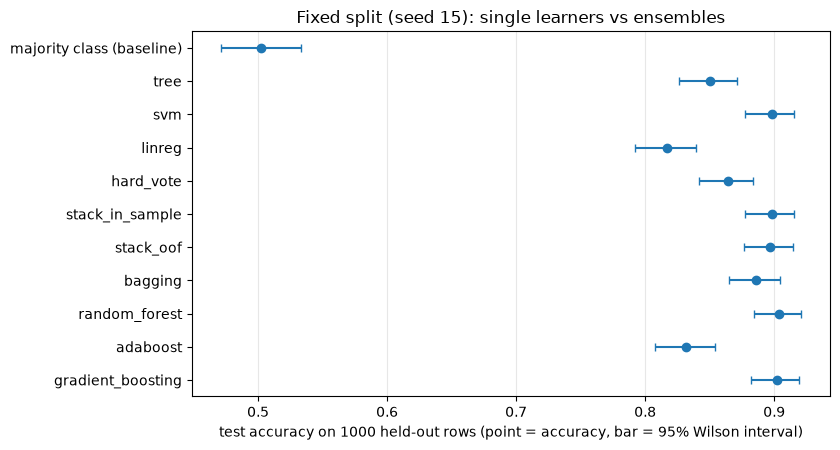

In [29]:
# ✅ Task 2 — every method fitted on the TRAINING rows only; scored on the 1000 held-out rows.
def run_all_methods(X_tr, y_tr, X_te, seed):
    # returns {method: (train_labels, test_labels)}, out-of-fold accuracy of every base learner, best single learner
    base = fit_base(X_tr, y_tr, seed)
    pred = {n: (as_label(n, m.predict(X_tr)), as_label(n, m.predict(X_te))) for n, m in base.items()}
    vote = lambda X: (np.column_stack([as_label(n, m.predict(X)) for n, m in base.items()]).sum(axis=1) >= 2).astype(int)
    pred["hard_vote"] = (vote(X_tr), vote(X_te))                                  # majority of the three base labels
    for protocol in ("in_sample", "oof"):
        meta, Z = fit_stack(base, X_tr, y_tr, seed, protocol)
        pred[f"stack_{protocol}"] = (meta.predict(base_predict(base, X_tr)), meta.predict(base_predict(base, X_te)))
        if protocol == "oof":
            cv_acc = {n: acc(as_label(n, Z[:, j]), y_tr) for j, n in enumerate(BASE_NAMES)}   # selection uses train rows only
    for name, est in {"bagging": BaggingClassifier(random_state=seed), "random_forest": RandomForestClassifier(random_state=seed),
                      "adaboost": AdaBoostClassifier(random_state=seed),
                      "gradient_boosting": GradientBoostingClassifier(random_state=seed)}.items():
        m = est.fit(X_tr, y_tr)
        pred[name] = (m.predict(X_tr), m.predict(X_te))
    return pred, cv_acc, max(cv_acc, key=cv_acc.get)

FAMILY = {"tree": "single: decision tree, depth 3", "svm": "single: SVC (RBF, defaults)",
          "linreg": "single: linear regression, thr. 0.5", "hard_vote": "ensemble: majority vote of the 3",
          "stack_in_sample": "ensemble: stacking, in-sample (provided)",
          "stack_oof": "ensemble: stacking, out-of-fold (fixed)", "bagging": "ensemble: bagging (defaults)",
          "random_forest": "ensemble: random forest (defaults)", "adaboost": "ensemble: AdaBoost (defaults)",
          "gradient_boosting": "ensemble: gradient boosting (defaults)"}

def wilson(k, n):
    ci = scipy.stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method="wilson")
    return ci.low, ci.high

def mcnemar_exact(y, pred_a, pred_b):
    a_only, b_only = int(np.sum((pred_a == y) & (pred_b != y))), int(np.sum((pred_a != y) & (pred_b == y)))
    n = a_only + b_only
    return a_only, b_only, (1.0 if n == 0 else float(scipy.stats.binomtest(a_only, n, 0.5).pvalue))

pred, cv_acc, best_single = run_all_methods(X_tr, y_tr, X_te, SEED)
maj = int(np.bincount(y_tr).argmax())
lo_b, hi_b = wilson((y_te == maj).sum(), len(y_te))
fixed_rows = [{"model": "majority class (baseline)", "family": "baseline", "train_acc": acc(maj, y_tr), "test_acc": acc(maj, y_te),
               "ci_low": lo_b, "ci_high": hi_b, "test_errors": int((y_te != maj).sum())}]
for name, fam in FAMILY.items():
    lo, hi = wilson((pred[name][1] == y_te).sum(), len(y_te))
    fixed_rows.append({"model": name, "family": fam, "train_acc": acc(pred[name][0], y_tr), "test_acc": acc(pred[name][1], y_te),
                       "ci_low": lo, "ci_high": hi, "test_errors": int((pred[name][1] != y_te).sum())})
fixed_df = pd.DataFrame(fixed_rows).set_index("model")
display(fixed_df.round(4))

stack_only, best_only, mc_p = mcnemar_exact(y_te, pred["stack_oof"][1], pred[best_single][1])
print(f"best single learner by OUT-OF-FOLD accuracy on the training rows: {best_single}  (out-of-fold accuracies: "
      + ", ".join(f"{n} {a:.3f}" for n, a in cv_acc.items()) + ")")
print(f"stack(out-of-fold) vs {best_single} on the test rows: stack right/{best_single} wrong = {stack_only}, "
      f"{best_single} right/stack wrong = {best_only}, McNemar exact p = {mc_p:.3f}")

order = list(fixed_df.index)[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.errorbar(fixed_df.loc[order, "test_acc"], range(len(order)),
            xerr=[fixed_df.loc[order, "test_acc"] - fixed_df.loc[order, "ci_low"], fixed_df.loc[order, "ci_high"] - fixed_df.loc[order, "test_acc"]],
            fmt="o", capsize=3)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("test accuracy on 1000 held-out rows (point = accuracy, bar = 95% Wilson interval)")
ax.set_title("Fixed split (seed 15): single learners vs ensembles")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### ✅ How wrong is Part A's 0.949? — an honest estimate on the *provided* 1000-row dataset

Part A's data (`x_train, y_train`, seed 15, 1000 rows) can be evaluated honestly without drawing new data: **outer 5-fold cross-validation**. In every outer fold the whole pipeline — base learners *and* the out-of-fold stacking — is fitted on the 800 training rows only and scored on the 200 held-out rows; the 5 × 200 held-out predictions cover each row exactly once.

In [30]:
# ✅ Honest accuracy of the provided pipeline on the provided dataset (outer 5-fold CV), next to its in-sample accuracy.
insample_pred, _, _ = run_all_methods(x_train, y_train, x_train, SEED)         # fit on all 1000 rows, score on the same rows
pooled = {}
for fit_idx, hold_idx in StratifiedKFold(5, shuffle=True, random_state=SEED).split(x_train, y_train):
    p, _, _ = run_all_methods(x_train[fit_idx], y_train[fit_idx], x_train[hold_idx], SEED)
    for name, (_, p_hold) in p.items():
        pooled.setdefault(name, np.empty(len(y_train), dtype=int))[hold_idx] = p_hold
outer_df = pd.DataFrame({"in-sample accuracy (as Part A)": {n: acc(insample_pred[n][1], y_train) for n in FAMILY},
                         "honest outer-CV accuracy": {n: acc(pooled[n], y_train) for n in FAMILY}})
outer_df["optimism"] = outer_df.iloc[:, 0] - outer_df.iloc[:, 1]
display(outer_df.loc[["tree", "svm", "linreg", "stack_in_sample", "stack_oof"]].round(4))
print(f"Part A printed {part_a_test_acc:.3f} as 'test accuracy' for the provided stack; the honest estimate for the same "
      f"pipeline on the same data is {outer_df.loc['stack_in_sample', 'honest outer-CV accuracy']:.3f}.")

,in-sample accuracy (as Part A),honest outer-CV accuracy,optimism
tree,0.911,0.897,0.014
svm,0.949,0.942,0.007
linreg,0.922,0.917,0.005
stack_in_sample,0.949,0.942,0.007
stack_oof,0.949,0.942,0.007


Part A printed 0.949 as 'test accuracy' for the provided stack; the honest estimate for the same pipeline on the same data is 0.942.


### ✅ Task 3 — is the result a lucky split? 50 independent datasets

`random_state` changes the problem itself (see F1), so 50 different seeds give 50 *different but statistically similar* problems. Each one is drawn once, split 50/50 stratified and processed by exactly the same code as above (`run_all_methods`). The datasets differ a lot in difficulty, therefore methods are compared **pairwise within a dataset**: difference to the best single learner (chosen by out-of-fold accuracy on that dataset's training rows), with a 95 % t-interval over the 50 differences and win/tie/loss counts.

,mean_test_acc,std_across_datasets,mean_diff,ci_low,ci_high,wins,ties,losses
tree,0.9363,0.0444,-0.0186,-0.0243,-0.0130,1,7,42
svm,0.9549,0.0335,-0.0000,-0.0004,0.0003,3,44,3
linreg,0.9359,0.0438,-0.0190,-0.0233,-0.0146,1,5,44
hard_vote,0.9491,0.0378,-0.0058,-0.0077,-0.0038,3,9,38
stack_in_sample,0.9537,0.0345,-0.0012,-0.0026,0.0001,8,20,22
stack_oof,0.9552,0.0336,0.0003,-0.0006,0.0012,7,38,5
bagging,0.9516,0.0333,-0.0033,-0.0064,-0.0001,17,1,32
random_forest,0.9577,0.0314,0.0028,0.0001,0.0055,29,4,17
adaboost,0.9411,0.0434,-0.0138,-0.0179,-0.0096,4,1,45
gradient_boosting,0.9542,0.0325,-0.0007,-0.0031,0.0016,20,3,27


best single learner chosen by out-of-fold accuracy, count over 50 datasets: {'svm': 42, 'tree': 6, 'linreg': 2}
stack(out-of-fold) − stack(in-sample): {'mean_diff': 0.0016, 'ci_low': 0.0004, 'ci_high': 0.0028, 'wins': 22, 'ties': 23, 'losses': 5, 'sign_test_p': 0.0015}


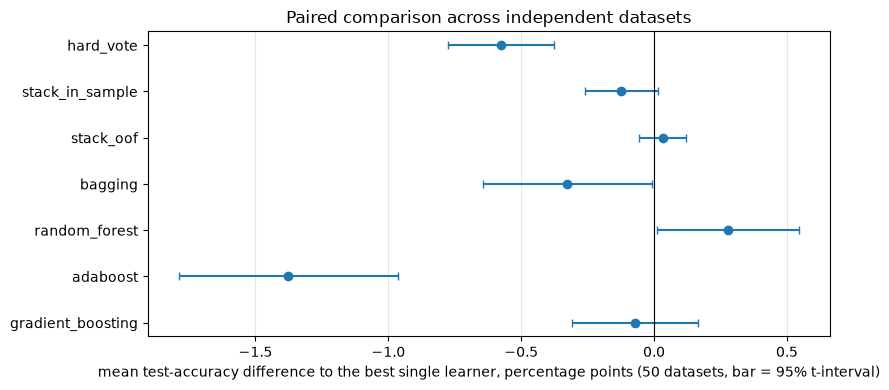

In [31]:
# ✅ Task 3 — 50 independent datasets (seeds 1000..1049), identical pipeline, paired comparison.
R = 50
rep_acc, rep_best, rep_best_name = [], [], []
for s in range(1000, 1000 + R):
    a_tr, a_te, b_tr, b_te = make_split(s)
    p, cv_a, best = run_all_methods(a_tr, b_tr, a_te, s)
    rep_acc.append({n: acc(p[n][1], b_te) for n in FAMILY})
    rep_best.append(acc(p[best][1], b_te))
    rep_best_name.append(best)
rep_acc, rep_best = pd.DataFrame(rep_acc), pd.Series(rep_best)

def paired(d):
    d = np.asarray(d, dtype=float)
    m, se = d.mean(), d.std(ddof=1) / np.sqrt(len(d))
    lo, hi = (m, m) if se == 0 else scipy.stats.t.interval(0.95, len(d) - 1, loc=m, scale=se)
    return {"mean_diff": float(m), "ci_low": float(lo), "ci_high": float(hi),
            "wins": int((d > 0).sum()), "ties": int((d == 0).sum()), "losses": int((d < 0).sum())}

rep_stats = pd.DataFrame({n: {"mean_test_acc": rep_acc[n].mean(), "std_across_datasets": rep_acc[n].std(ddof=1),
                              **paired(rep_acc[n] - rep_best)} for n in FAMILY}).T
rep_stats[["wins", "ties", "losses"]] = rep_stats[["wins", "ties", "losses"]].astype(int)
display(rep_stats.round(4))
print("best single learner chosen by out-of-fold accuracy, count over", R, "datasets:", pd.Series(rep_best_name).value_counts().to_dict())

oof_vs_in = paired(rep_acc["stack_oof"] - rep_acc["stack_in_sample"])
n_nt = oof_vs_in["wins"] + oof_vs_in["losses"]
oof_vs_in["sign_test_p"] = float(scipy.stats.binomtest(oof_vs_in["wins"], n_nt, 0.5).pvalue) if n_nt else 1.0
print("stack(out-of-fold) − stack(in-sample):", {k: round(v, 4) if isinstance(v, float) else v for k, v in oof_vs_in.items()})

methods = [n for n in FAMILY if n not in ("tree", "svm", "linreg")][::-1]        # first method drawn at the top
d_pp, lo_pp, hi_pp = (100 * rep_stats.loc[methods, c] for c in ("mean_diff", "ci_low", "ci_high"))
fig, ax = plt.subplots(figsize=(8.5, 4.0))
ax.errorbar(d_pp, range(len(methods)), xerr=[d_pp - lo_pp, hi_pp - d_pp], fmt="o", capsize=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(methods)), methods)
ax.set_xlabel(f"mean test-accuracy difference to the best single learner, percentage points ({R} datasets, bar = 95% t-interval)")
ax.set_title("Paired comparison across independent datasets")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### ✅ Stress test for F2 — when the in-sample protocol really breaks

With the provided low-capacity base learners the in-sample leak is small. The leak is a property of the *method*, though, and it bites whenever a base learner can memorise its training rows. Same experiment, but the base decision tree is **unpruned** (`max_depth=None`): on its own training rows it is right 100 % of the time, so an in-sample meta-learner learns "just copy the tree".

In [32]:
# ✅ Stress test: base learners = unpruned tree + SVC + LinearRegression (everything else unchanged).
deep = lambda seed: make_base_learners(seed, tree_depth=None)

def stack_scores(X_tr, y_tr, X_te, y_te, seed, factory):
    base_ = fit_base(X_tr, y_tr, seed, factory)
    out = {n: (acc(as_label(n, m.predict(X_tr)), y_tr), acc(as_label(n, m.predict(X_te)), y_te)) for n, m in base_.items()}
    for protocol in ("in_sample", "oof"):
        meta_, _ = fit_stack(base_, X_tr, y_tr, seed, protocol, factory)
        out[f"stack_{protocol}"] = (acc(meta_.predict(base_predict(base_, X_tr)), y_tr), acc(meta_.predict(base_predict(base_, X_te)), y_te))
    return out

fixed_deep = stack_scores(X_tr, y_tr, X_te, y_te, SEED, deep)
display(pd.DataFrame(fixed_deep, index=["train acc", "test acc"]).T.round(4))
rep_deep = []
for s in range(1000, 1000 + R):
    a_tr, a_te, b_tr, b_te = make_split(s)
    rep_deep.append({n: v[1] for n, v in stack_scores(a_tr, b_tr, a_te, b_te, s, deep).items()})
rep_deep = pd.DataFrame(rep_deep)
stress = {"fixed_split_test_acc": {n: v[1] for n, v in fixed_deep.items()},
          "mean_test_acc_over_datasets": rep_deep.mean().to_dict(),
          "oof_minus_in_sample": paired(rep_deep["stack_oof"] - rep_deep["stack_in_sample"])}
print(f"{R} datasets, unpruned tree: mean test acc " + ", ".join(f"{n} {a:.4f}" for n, a in rep_deep.mean().items()))
print("stack(out-of-fold) − stack(in-sample):", {k: round(v, 4) if isinstance(v, float) else v for k, v in stress["oof_minus_in_sample"].items()})

,train acc,test acc
tree,1.000,0.838
svm,0.892,0.898
linreg,0.797,0.817
stack_in_sample,1.000,0.838
stack_oof,0.892,0.898


50 datasets, unpruned tree: mean test acc tree 0.9357, svm 0.9549, linreg 0.9359, stack_in_sample 0.9357, stack_oof 0.9547
stack(out-of-fold) − stack(in-sample): {'mean_diff': 0.019, 'ci_low': 0.0147, 'ci_high': 0.0234, 'wins': 46, 'ties': 3, 'losses': 1}


### ✅ Why does stacking add so little here? — what the meta-learner actually learned

Fixed split, out-of-fold stack. Rows of the table = the possible combinations of the three base outputs (tree label, SVM label, linear output above/below 0.5); `stack says 1` = share of test rows in that group the stack classifies as class 1.

In [33]:
# ✅ Interpretation of the stack on the test set (fixed split, out-of-fold protocol).
stack_te = stack["oof"].predict(Z_test)
combo = pd.DataFrame({"tree": Z_test[:, 0].astype(int), "svm": Z_test[:, 1].astype(int),
                      "linreg>0.5": (Z_test[:, 2] > 0.5).astype(int), "stack": stack_te, "y": y_te})
why = combo.groupby(["tree", "svm", "linreg>0.5"]).agg(rows=("y", "size"), stack_says_1=("stack", "mean"), true_share_1=("y", "mean"))
display(why.round(3))
agree_svm = float(np.mean(stack_te == Z_test[:, 1]))
svm_err = Z_test[:, 1] != y_te
overlap_tree = float(np.mean(Z_test[svm_err, 0] != y_te[svm_err]))
overlap_lin = float(np.mean((Z_test[svm_err, 2] > 0.5).astype(int) != y_te[svm_err]))
print(f"stack agrees with the SVM base learner on {agree_svm:.1%} of the test rows")
print(f"of the SVM's {int(svm_err.sum())} test errors, {overlap_tree:.0%} are also misclassified by the tree and "
      f"{overlap_lin:.0%} by the linear model (errors are strongly shared)")

rows  stack_says_1  true_share_1
tree svm linreg>0.5                                  
0    0   0            447         0.000         0.112
         1             16         0.000         0.000
     1   0             25         1.000         0.680
         1              6         1.000         0.667
1    0   0             30         0.167         0.300
         1             31         0.000         0.097
     1   0             43         1.000         0.860
         1            402         1.000         0.940

stack agrees with the SVM base learner on 99.5% of the test rows
of the SVM's 102 test errors, 78% are also misclassified by the tree and 83% by the linear model (errors are strongly shared)


In [34]:
# ✅ Save every reported number (written by this notebook; the verification script re-computes them independently).
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return round(float(o), 12)          # drop binary-float noise such as 0.014000000000000012
    if isinstance(o, (np.bool_, bool)):
        return bool(o)
    return o

results = clean({
    "environment": {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
                    "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__, "compute": "cpu"},
    "part_a_provided_protocol": {"x_test_identical_to_x_train": same_x, "y_test_identical_to_y_train": same_y,
                                 "reported_train_accuracy": part_a_train_acc, "reported_test_accuracy": part_a_test_acc},
    "honest_estimate_on_provided_dataset": {"method": "outer 5-fold CV, StratifiedKFold(shuffle, seed 15), pooled predictions",
                                            "table": outer_df.to_dict(orient="index")},
    "fixed_split": {"seed": SEED, "n_pool": 2000, "n_train": len(y_tr), "n_test": len(y_te), "k_folds": K_FOLDS,
                    "table": fixed_df.to_dict(orient="index"), "oof_cv_accuracy_of_base_learners": cv_acc,
                    "best_single_by_oof_cv": best_single,
                    "mcnemar_stack_oof_vs_best_single": {"stack_only_right": stack_only, "best_single_only_right": best_only, "p": mc_p},
                    "sklearn_crosscheck": sklearn_crosscheck,
                    "stack_agreement_with_svm": agree_svm},
    "replicates": {"n_datasets": R, "seeds": list(range(1000, 1000 + R)), "table": rep_stats.to_dict(orient="index"),
                   "stack_oof_minus_stack_in_sample": oof_vs_in, "best_single_counts": pd.Series(rep_best_name).value_counts().to_dict()},
    "stress_test_unpruned_tree": stress,
})
with open("ensemble_results.json", "w", encoding="utf-8") as fh:
    json.dump(results, fh, indent=2)
print("saved ensemble_results.json with", len(json.dumps(results)), "characters")

saved ensemble_results.json with 6998 characters


In [35]:
# ✅ Conclusions — generated from the numbers computed above (so they cannot go stale).
pp = lambda x: f"{100 * x:+.2f} pp"
def verdict(s):
    return "no detectable difference" if s["ci_low"] <= 0 <= s["ci_high"] else ("a small gain" if s["mean_diff"] > 0 else "a small loss")

ft = fixed_df["test_acc"]
st = rep_stats.loc["stack_oof"]
oth = ", ".join(f"{n} {pp(rep_stats.loc[n, 'mean_diff'])} [{pp(rep_stats.loc[n, 'ci_low'])}, {pp(rep_stats.loc[n, 'ci_high'])}]"
                for n in ("hard_vote", "bagging", "random_forest", "adaboost", "gradient_boosting"))
display(Markdown(f'''
**Conclusions** (every number below is computed by this notebook)

1. **Part A's "test accuracy" is not a test accuracy (F1, critical).** It prints {part_a_test_acc:.3f} for "train" and "test" alike because the test arrays are the training arrays. The honest estimate of the *same* pipeline on the *same* 1000 rows (outer 5-fold CV) is **{outer_df.loc['stack_in_sample', 'honest outer-CV accuracy']:.3f}**; the provided figure is optimistic by {100 * outer_df.loc['stack_in_sample', 'optimism']:.1f} pp (small only because all three base learners are low-capacity — the point is that it is an in-sample number, not a test result).
2. **Ensemble vs. its parts (R5, R6; fixed 1000/1000 split).** Test accuracy: tree {ft['tree']:.3f}, SVM {ft['svm']:.3f}, linear {ft['linreg']:.3f}, majority vote {ft['hard_vote']:.3f}, **stack (out-of-fold) {ft['stack_oof']:.3f}**. The best single learner by out-of-fold accuracy on the training rows is **{best_single}** ({ft[best_single]:.3f} on test); the stack gains {stack_only} and loses {best_only} test rows relative to it (McNemar exact p = {mc_p:.2f}) — {'no detectable difference' if mc_p > 0.05 else 'a significant difference'}.
3. **Not a lucky split ({R} independent datasets).** Stack minus best single learner: **{pp(st['mean_diff'])}** (95 % CI [{pp(st['ci_low'])}, {pp(st['ci_high'])}]; {int(st['wins'])} wins / {int(st['ties'])} ties / {int(st['losses'])} losses) → {verdict(st)}. Other ensembles vs. the same reference (context only; these intervals are not adjusted for the many comparisons, so a borderline interval is weak evidence): {oth}.
4. **In-sample vs. out-of-fold (F2).** With the provided low-capacity base learners the out-of-fold protocol is {pp(oof_vs_in['mean_diff'])} better (95 % CI [{pp(oof_vs_in['ci_low'])}, {pp(oof_vs_in['ci_high'])}], sign-test p = {oof_vs_in['sign_test_p']:.3f}) — real but small. With an *unpruned* tree as a base learner the in-sample stack collapses to that tree (mean test accuracy {stress['mean_test_acc_over_datasets']['stack_in_sample']:.4f} vs. {stress['mean_test_acc_over_datasets']['stack_oof']:.4f} out-of-fold, difference {pp(stress['oof_minus_in_sample']['mean_diff'])}). The out-of-fold protocol is the correct one whatever the base learners are.
5. **Why stacking adds little here.** The meta-learner agrees with the SVM on {agree_svm:.1%} of the test rows, and {overlap_tree:.0%} / {overlap_lin:.0%} of the SVM's errors are also made by the tree / the linear model: the extra learners are weaker and fail on the same (hard or label-noise) rows, so there is nothing for a combiner to exploit. Stacking helps when base learners are comparably strong *and* err on different rows.
'''))


**Conclusions** (every number below is computed by this notebook)

1. **Part A's "test accuracy" is not a test accuracy (F1, critical).** It prints 0.949 for "train" and "test" alike because the test arrays are the training arrays. The honest estimate of the *same* pipeline on the *same* 1000 rows (outer 5-fold CV) is **0.942**; the provided figure is optimistic by 0.7 pp (small only because all three base learners are low-capacity — the point is that it is an in-sample number, not a test result).
2. **Ensemble vs. its parts (R5, R6; fixed 1000/1000 split).** Test accuracy: tree 0.850, SVM 0.898, linear 0.817, majority vote 0.864, **stack (out-of-fold) 0.897**. The best single learner by out-of-fold accuracy on the training rows is **svm** (0.898 on test); the stack gains 2 and loses 3 test rows relative to it (McNemar exact p = 1.00) — no detectable difference.
3. **Not a lucky split (50 independent datasets).** Stack minus best single learner: **+0.03 pp** (95 % CI [-0.06 pp, +0.12 pp]; 7 wins / 38 ties / 5 losses) → no detectable difference. Other ensembles vs. the same reference (context only; these intervals are not adjusted for the many comparisons, so a borderline interval is weak evidence): hard_vote -0.58 pp [-0.77 pp, -0.38 pp], bagging -0.33 pp [-0.64 pp, -0.01 pp], random_forest +0.28 pp [+0.01 pp, +0.55 pp], adaboost -1.38 pp [-1.79 pp, -0.96 pp], gradient_boosting -0.07 pp [-0.31 pp, +0.16 pp].
4. **In-sample vs. out-of-fold (F2).** With the provided low-capacity base learners the out-of-fold protocol is +0.16 pp better (95 % CI [+0.04 pp, +0.28 pp], sign-test p = 0.002) — real but small. With an *unpruned* tree as a base learner the in-sample stack collapses to that tree (mean test accuracy 0.9357 vs. 0.9547 out-of-fold, difference +1.90 pp). The out-of-fold protocol is the correct one whatever the base learners are.
5. **Why stacking adds little here.** The meta-learner agrees with the SVM on 99.5% of the test rows, and 78% / 83% of the SVM's errors are also made by the tree / the linear model: the extra learners are weaker and fail on the same (hard or label-noise) rows, so there is nothing for a combiner to exploit. Stacking helps when base learners are comparably strong *and* err on different rows.


### ✅ Requirement checklist (R1–R6) — where each one is completed

| Req | Completed in | Result |
|---|---|---|
| **R1** data | *Task 1* data cell | one draw of 2000 rows → train `(1000, 6)` + test `(1000, 6)`, stratified, no shared row (Part A's own data cell is kept unchanged and shown to be defective: F1) |
| **R2** base learners | *R2* cell and helper `make_base_learners` | decision tree (depth 3), `SVC()`, `LinearRegression()` fitted on the training rows only; in-sample vs. out-of-fold accuracy reported |
| **R3** stacked matrix | *R3 + R4* cell | `(1000, 3)` matrices for train and test, for both protocols |
| **R4** meta-learner | *R3 + R4* cell | `SVC()` meta-learner trained on in-sample (provided) and on out-of-fold (fixed) features; the out-of-fold version is cross-checked against `cross_val_predict` and `StackingClassifier` |
| **R5** accuracies | *Task 2* table | train **and test** accuracy of every method on held-out rows, plus the honest estimate for the provided dataset |
| **R6** comparison | *Tasks 2, 3* and the stress test | ensemble vs. each base learner, vs. majority vote, bagging, random forest, AdaBoost and gradient boosting — on the fixed split and on 50 independent datasets |

**Limits of this study.** Synthetic, i.i.d. data (`make_classification`, 1 % label noise built in), so absolute accuracies say nothing about real data; only the *protocol* conclusions transfer. The metric is plain accuracy, which is appropriate here because the classes are balanced (502 / 498 in the training rows); with imbalanced data use F1 / PR-AUC instead. All models use library defaults — no hyper-parameter tuning was done for any method, so the comparison with the non-stacking ensembles is indicative, not a tuned benchmark. One stacking recipe (K = 5 folds, SVC meta-learner, hard labels + raw regression output) was studied. Differences of about two percentage points or less on a single 1000-row test set are within sampling noise; the 50-dataset comparison is what supports the conclusions about stacking. CPU only — nothing here needs a GPU.